In [2]:
# FactoryLens | Notebook 2 — Business Layer Creation & EDA
# Step 1: Reload libraries and cleaned dataset

import pandas as pd
import numpy as np

# Reload your cleaned dataset
data_path = r"C:\Users\yashp\Downloads\MyFactoryLens\ai4i+2020+predictive+maintenance+dataset\ai4i2020.csv"
df = pd.read_csv(data_path)

# Reapply the column cleaning from Notebook 1
df = df.rename(columns={
    'UDI': 'udi',
    'Product ID': 'product_id',
    'Type': 'product_type',
    'Air temperature [K]': 'air_temp_k',
    'Process temperature [K]': 'process_temp_k',
    'Rotational speed [rpm]': 'rotational_speed_rpm',
    'Torque [Nm]': 'torque_nm',
    'Tool wear [min]': 'tool_wear_min',
    'Machine failure': 'machine_failure',
    'TWF': 'failure_twf',
    'HDF': 'failure_hdf',
    'PWF': 'failure_pwf',
    'OSF': 'failure_osf',
    'RNF': 'failure_rnf'
})

print(f"✅ Dataset reloaded and cleaned. Shape: {df.shape}")
df.head()

✅ Dataset reloaded and cleaned. Shape: (10000, 14)


,udi,product_id,product_type,air_temp_k,process_temp_k,rotational_speed_rpm,torque_nm,tool_wear_min,machine_failure,failure_twf,failure_hdf,failure_pwf,failure_osf,failure_rnf
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
# Cell 2 — Create the shift column

# Define shift order
shift_options = ['Morning', 'Evening', 'Night']

# Assign shifts by cycling through rows
# row index % 3 gives 0, 1, or 2 repeatedly
df['shift'] = [shift_options[i % 3] for i in range(len(df))]

print("✅ Shift column created.")
print("\nShift distribution:")
print(df['shift'].value_counts())

✅ Shift column created.

Shift distribution:
shift
Morning    3334
Evening    3333
Night      3333
Name: count, dtype: int64


In [4]:
# Cell 3 — Create operator_experience column
# Probabilities are linked to shift — not purely random
# Business assumption: Morning attracts more experienced operators
# Night shifts have more junior operators due to staffing patterns

np.random.seed(42)

# Define experience probabilities per shift
shift_experience_map = {
    'Morning': {'probs': [0.20, 0.40, 0.40], 
                'levels': ['Junior', 'Senior', 'Expert']},
    'Evening': {'probs': [0.34, 0.33, 0.33], 
                'levels': ['Junior', 'Senior', 'Expert']},
    'Night':   {'probs': [0.50, 0.30, 0.20], 
                'levels': ['Junior', 'Senior', 'Expert']}
}

# Assign experience level row by row based on shift
operator_exp = []

for shift in df['shift']:
    probs  = shift_experience_map[shift]['probs']
    levels = shift_experience_map[shift]['levels']
    chosen = np.random.choice(levels, p=probs)
    operator_exp.append(chosen)

df['operator_experience'] = operator_exp

print("✅ Operator experience column created.")
print("\nOverall distribution:")
print(df['operator_experience'].value_counts())

print("\nDistribution by shift:")
print(pd.crosstab(df['shift'], df['operator_experience']))

✅ Operator experience column created.

Overall distribution:
operator_experience
Junior    3519
Senior    3457
Expert    3024
Name: count, dtype: int64

Distribution by shift:
operator_experience  Expert  Junior  Senior
shift                                      
Evening                1044    1154    1135
Morning                1350     634    1350
Night                   630    1731     972


In [5]:
# Cell 4 — Create machine_age_category
# Derived from tool_wear_min using mechanical thresholds
# Business logic: higher tool wear = older machine state = higher risk

df['machine_age_category'] = pd.cut(
    df['tool_wear_min'],
    bins=[-1, 100, 160, 200, 300],
    labels=['New', 'Mid-life', 'Aging', 'Critical']
)

print("✅ Machine age category created.")
print("\nDistribution:")
print(df['machine_age_category'].value_counts().sort_index())

✅ Machine age category created.

Distribution:
machine_age_category
New         4667
Mid-life    2745
Aging       1826
Critical     762
Name: count, dtype: int64


In [6]:
# Cell 5 — Create maintenance_status
# Rule-based business alert derived from tool_wear_min
# Mirrors real maintenance scheduling logic in manufacturing

df['maintenance_status'] = np.where(
    df['tool_wear_min'] > 200, 'Overdue',
    np.where(
        df['tool_wear_min'] > 150, 'Due Soon', 'OK'
    )
)

print("✅ Maintenance status created.")
print("\nDistribution:")
print(df['maintenance_status'].value_counts())

✅ Maintenance status created.

Distribution:
maintenance_status
OK          6962
Due Soon    2276
Overdue      762
Name: count, dtype: int64


In [7]:
# Cell 6 — Verify enriched dataset and save

print("=== ENRICHED DATASET SHAPE ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")

print("\n=== ALL COLUMNS ===")
print(df.columns.tolist())

print("\n=== FIRST 3 ROWS — BUSINESS LAYER VISIBLE ===")
display(df[['udi', 'tool_wear_min', 'machine_failure',
            'shift', 'operator_experience',
            'machine_age_category', 'maintenance_status']].head(3))

# Save enriched dataset
save_path = r"C:\Users\yashp\Downloads\MyFactoryLens\MyFactorylens_dataset.csv"
df.to_csv(save_path, index=False)

print(f"\n✅ Enriched dataset saved to: {save_path}")
print("This file will be used in all future notebooks.")

=== ENRICHED DATASET SHAPE ===
Rows: 10000, Columns: 18

=== ALL COLUMNS ===
['udi', 'product_id', 'product_type', 'air_temp_k', 'process_temp_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'failure_twf', 'failure_hdf', 'failure_pwf', 'failure_osf', 'failure_rnf', 'shift', 'operator_experience', 'machine_age_category', 'maintenance_status']

=== FIRST 3 ROWS — BUSINESS LAYER VISIBLE ===


,udi,tool_wear_min,machine_failure,shift,operator_experience,machine_age_category,maintenance_status
0,1,0,0,Morning,Senior,New,OK
1,2,3,0,Evening,Expert,New,OK
2,3,5,0,Night,Senior,New,OK



✅ Enriched dataset saved to: C:\Users\yashp\Downloads\MyFactoryLens\MyFactorylens_dataset.csv
This file will be used in all future notebooks.


## EDA

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.titleweight'] = 'bold'

print("✅ Visualization libraries ready.")

✅ Visualization libraries ready.


#Which shift has the highest failure rate?
Understanding before typing:

Failure Rate by Shift:
     Shift  Failure Rate (%)
0  Evening          3.660366
2    Night          3.330333
1  Morning          3.179364


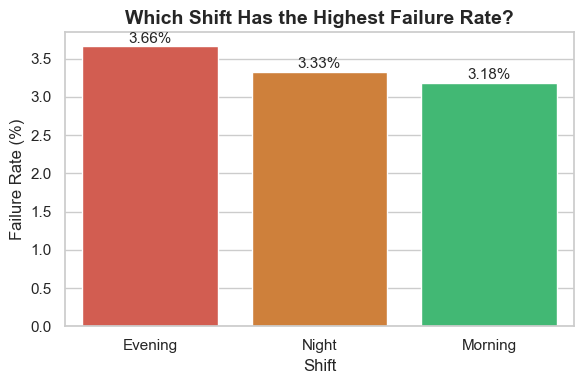

✅ Chart 1 done.


In [9]:
# ==============================
# Business Question 1
# Which shift has the highest failure rate?
# ==============================

# Calculate failure rate per shift
shift_failure = df.groupby('shift')['machine_failure'].mean() * 100
shift_failure = shift_failure.reset_index()
shift_failure.columns = ['Shift', 'Failure Rate (%)']
shift_failure = shift_failure.sort_values(
    'Failure Rate (%)',
    ascending=False
)

print("Failure Rate by Shift:")
print(shift_failure)

# Visualization
plt.figure(figsize=(6, 4))

sns.barplot(
    x='Shift',
    y='Failure Rate (%)',
    data=shift_failure,
    hue='Shift',
    palette=['#e74c3c', '#e67e22', '#2ecc71'],
    legend=False
)

# Add value labels
for i, row in shift_failure.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row['Failure Rate (%)'] + 0.05,
        f"{row['Failure Rate (%)']:.2f}%",
        ha='center',
        fontsize=11
    )

plt.title("Which Shift Has the Highest Failure Rate?")
plt.xlabel("Shift")
plt.ylabel("Failure Rate (%)")

plt.tight_layout()
plt.savefig("chart1_shift_failure_rate.png", dpi=150)
plt.show()

print("✅ Chart 1 done.")

Tool Wear Statistics by Failure Status:
                count    mean    std  min   25%    50%    75%    max
failure_label                                                       
Failure         339.0  143.78  72.76  0.0  84.5  165.0  207.5  253.0
No Failure     9661.0  106.69  62.95  0.0  52.0  107.0  160.0  246.0


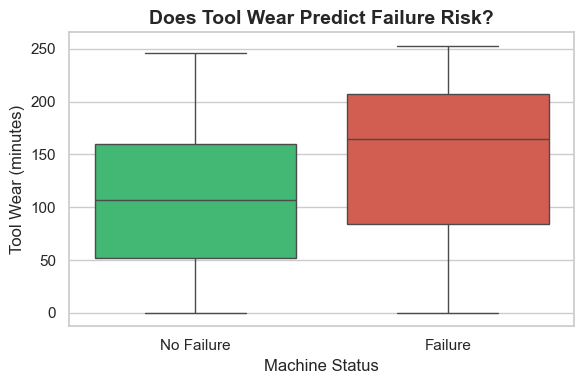

✅ Chart 2 done.


In [10]:
# Business Question 2: Does tool wear predict failure risk?

# Create readable labels for machine_failure
df['failure_label'] = df['machine_failure'].map({
    0: 'No Failure',
    1: 'Failure'
})

# Print summary statistics to understand the numbers
print("Tool Wear Statistics by Failure Status:")
print(df.groupby('failure_label')['tool_wear_min'].describe().round(2))

# Visualization
plt.figure(figsize=(6, 4))

sns.boxplot(
    x='failure_label',
    y='tool_wear_min',
    data=df,
    hue='failure_label',
    palette={'No Failure': '#2ecc71', 'Failure': '#e74c3c'},
    legend=False
)

plt.title("Does Tool Wear Predict Failure Risk?")
plt.xlabel("Machine Status")
plt.ylabel("Tool Wear (minutes)")
plt.tight_layout()
plt.savefig("chart2_toolwear_failure.png", dpi=150)
plt.show()

print("✅ Chart 2 done.")

Failure Rate by Product Type:
  Product Type  Failure Rate (%)
1            L          3.916667
2            M          2.769436
0            H          2.093719

Raw counts for context:
  Product Type  Total Failures  Total Rows
0            H              21        1003
1            L             235        6000
2            M              83        2997


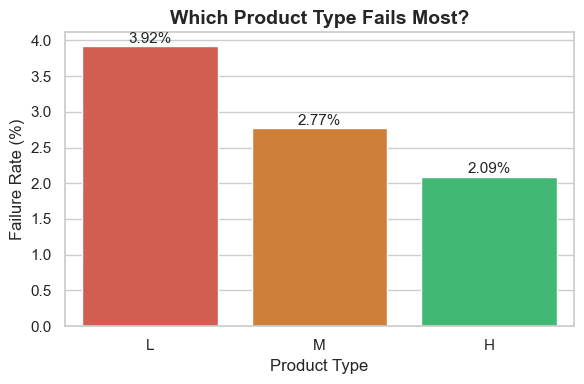

✅ Chart 3 done.


In [11]:
# Business Question 3: Which product type fails most?

# Calculate failure rate per product type
product_failure = df.groupby('product_type')['machine_failure'].mean() * 100
product_failure = product_failure.reset_index()
product_failure.columns = ['Product Type', 'Failure Rate (%)']
product_failure = product_failure.sort_values(
    'Failure Rate (%)',
    ascending=False
)

# Also get raw counts for context
product_counts = df.groupby('product_type')['machine_failure'].agg(
    ['sum', 'count']
).reset_index()
product_counts.columns = ['Product Type', 'Total Failures', 'Total Rows']

print("Failure Rate by Product Type:")
print(product_failure)
print("\nRaw counts for context:")
print(product_counts)

# Visualization
plt.figure(figsize=(6, 4))

sns.barplot(
    x='Product Type',
    y='Failure Rate (%)',
    data=product_failure,
    hue='Product Type',
    palette=['#e74c3c', '#e67e22', '#2ecc71'],
    legend=False
)

# Add value labels
for i, row in product_failure.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row['Failure Rate (%)'] + 0.05,
        f"{row['Failure Rate (%)']:.2f}%",
        ha='center',
        fontsize=11
    )

plt.title("Which Product Type Fails Most?")
plt.xlabel("Product Type")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.savefig("chart3_producttype_failure.png", dpi=150)
plt.show()

print("✅ Chart 3 done.")

Failure Rate by Operator Experience:
  Operator Experience  Failure Rate (%)
1              Junior          3.751066
0              Expert          3.472222
2              Senior          2.950535


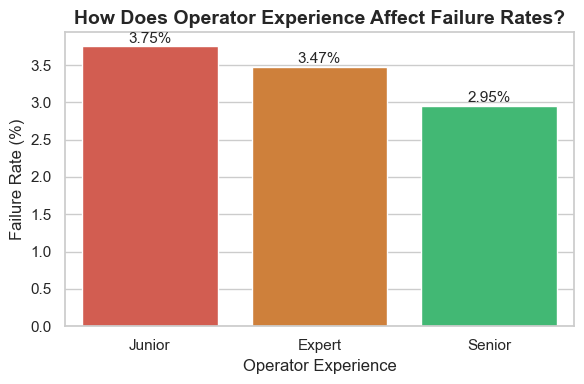

✅ Chart 4 done.


In [12]:
# Business Question 4: How does operator experience affect failure rates?

# Calculate failure rate per experience level
exp_failure = df.groupby('operator_experience')['machine_failure'].mean() * 100
exp_failure = exp_failure.reset_index()
exp_failure.columns = ['Operator Experience', 'Failure Rate (%)']
exp_failure = exp_failure.sort_values(
    'Failure Rate (%)',
    ascending=False
)

print("Failure Rate by Operator Experience:")
print(exp_failure)

# Visualization
plt.figure(figsize=(6, 4))

sns.barplot(
    x='Operator Experience',
    y='Failure Rate (%)',
    data=exp_failure,
    hue='Operator Experience',
    palette=['#e74c3c', '#e67e22', '#2ecc71'],
    legend=False
)

# Add value labels
for i, row in exp_failure.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row['Failure Rate (%)'] + 0.05,
        f"{row['Failure Rate (%)']:.2f}%",
        ha='center',
        fontsize=11
    )

plt.title("How Does Operator Experience Affect Failure Rates?")
plt.xlabel("Operator Experience")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.savefig("chart4_experience_failure.png", dpi=150)
plt.show()

print("✅ Chart 4 done.")

Temperature Difference by Failure Status:
                count   mean   std  min  25%  50%   75%   max
failure_label                                                
Failure         339.0   9.40  1.16  7.6  8.4  9.3  10.5  12.0
No Failure     9661.0  10.02  0.99  7.6  9.3  9.8  11.0  12.1


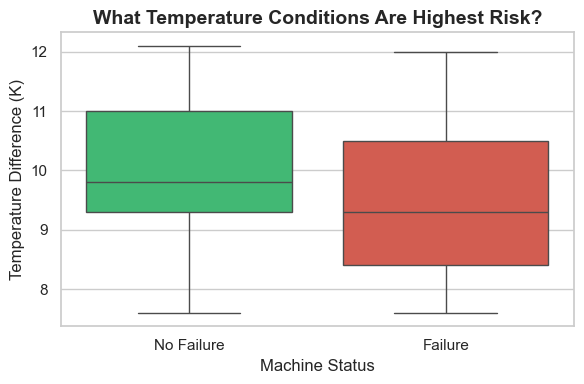

✅ Chart 5 done.


In [13]:
# Business Question 5: What temperature conditions are highest risk?

# Create temperature difference column
df['temp_diff'] = df['process_temp_k'] - df['air_temp_k']

# Summary statistics
print("Temperature Difference by Failure Status:")
print(df.groupby('failure_label')['temp_diff'].describe().round(2))

# Visualization
plt.figure(figsize=(6, 4))

sns.boxplot(
    x='failure_label',
    y='temp_diff',
    data=df,
    hue='failure_label',
    palette={'No Failure': '#2ecc71', 'Failure': '#e74c3c'},
    legend=False
)

plt.title("What Temperature Conditions Are Highest Risk?")
plt.xlabel("Machine Status")
plt.ylabel("Temperature Difference (K)")
plt.tight_layout()
plt.savefig("chart5_temp_failure.png", dpi=150)
plt.show()

print("✅ Chart 5 done.")

Failure Rate by Machine Age Category:
  Machine Age Category  Failure Rate (%)
0                  New          2.249839
1             Mid-life          2.112933
2                Aging          3.176342
3             Critical         15.485564


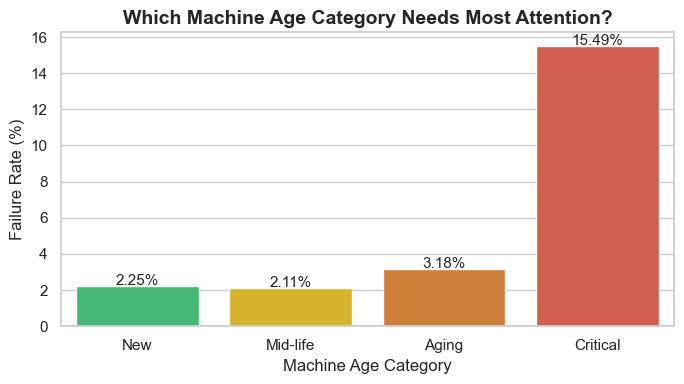

✅ Chart 6 done.


In [15]:
# Business Question 6: Which machine age category needs most attention?

# Calculate failure rate per machine age category
age_failure = df.groupby(
    'machine_age_category',
    observed=True
)['machine_failure'].mean() * 100
age_failure = age_failure.reset_index()
age_failure.columns = ['Machine Age Category', 'Failure Rate (%)']

# Define correct order — New to Critical
category_order = ['New', 'Mid-life', 'Aging', 'Critical']
age_failure['Machine Age Category'] = pd.Categorical(
    age_failure['Machine Age Category'],
    categories=category_order,
    ordered=True
)
age_failure = age_failure.sort_values('Machine Age Category')

print("Failure Rate by Machine Age Category:")
print(age_failure)

# Visualization
plt.figure(figsize=(7, 4))

sns.barplot(
    x='Machine Age Category',
    y='Failure Rate (%)',
    data=age_failure,
    hue='Machine Age Category',
    palette=['#2ecc71', '#f1c40f', '#e67e22', '#e74c3c'],
    legend=False,
    order=category_order
)

# Add value labels
for i, row in age_failure.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row['Failure Rate (%)'] + 0.05,
        f"{row['Failure Rate (%)']:.2f}%",
        ha='center',
        fontsize=11
    )

plt.title("Which Machine Age Category Needs Most Attention?")
plt.xlabel("Machine Age Category")
plt.ylabel("Failure Rate (%)")
plt.tight_layout()
plt.savefig("chart6_machineage_failure.png", dpi=150)
plt.show()

print("✅ Chart 6 done.")

## EDA Summary — Key Findings

### Business Questions Answered
1. **Shift vs Failure:** Evening shift highest at 3.66%
2. **Tool Wear vs Failure:** Failed machines median 58 min higher 
   tool wear than non-failures
3. **Product Type vs Failure:** L type fails at 3.92% — nearly 
   double H type at 2.09%
4. **Operator Experience vs Failure:** Junior highest at 3.75% 
   but experience alone doesn't fully explain failures
5. **Temperature vs Failure:** Lower temp difference correlates 
   with failure — poor heat dissipation is the risk signal
6. **Machine Age vs Failure:** Critical category fails at 15.49% 
   — 5x higher than all other categories

### Overall Conclusion
Failures are driven primarily by machine condition — tool wear 
crossing critical thresholds is the strongest single predictor. 
Product type and operator experience are secondary factors. 
No single variable explains everything — a combination of 
sensor readings and operational context drives risk.

### Next Step
Notebook 03 — Feature Engineering and ML Modeling